In [6]:
pip install imblearn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
   ---------------------------------------- 236.1/236.1 kB 7.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB 7.9 MB/s eta 0:00:07
    --------------------------------------- 0.7/48.9 MB 8.3 MB/s eta 0:00:06
    --------------------------------------- 1.2/48.9 MB 9.2 MB/s eta 0:00:06
   - -------------------------------------- 1.7/48.9 MB 9.8 MB/s eta 0:00:05
   - -------------------------------------- 2.3/48.9 MB 10.2 MB/s eta 0:00:05
   -- ------------------------------------- 2.6/48.9 MB 10.4 MB/s eta 0:00:05
   -- ------------------------------------- 3.1/48.9 MB 9.8 MB/s eta 0:00:05
   -- ------------------------------------- 3.5/48.9 MB 9.8 MB/s eta 0:00:05
   --- ------------------------------------ 4.0/48.9 MB 10.3 MB/s eta 0:00:05
   --- ------------------------------------ 4.2/48.9 MB 9.7 MB/s eta 0:00:05
   --- ------------------------------------ 4.4/48.9 MB 9.3 MB/s eta 0:00:05
  


[notice] A new release of pip is available: 24.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, average_precision_score

In [58]:
df = pd.read_csv("credit_card_fraud_2026.csv")
df.head()

,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,...,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,...,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,...,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,...,False,True,0,42.3,5,0,False,24.7,1,0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,...,False,False,0,28.9,22,6,False,56.2,1,0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,...,False,False,0,3.9,2,4,False,32.7,0,0


Fraud rate: 1.70%  (339 of 20000)
Accuracy of a "never fraud" model: 98.30%  <-- catches ZERO fraud


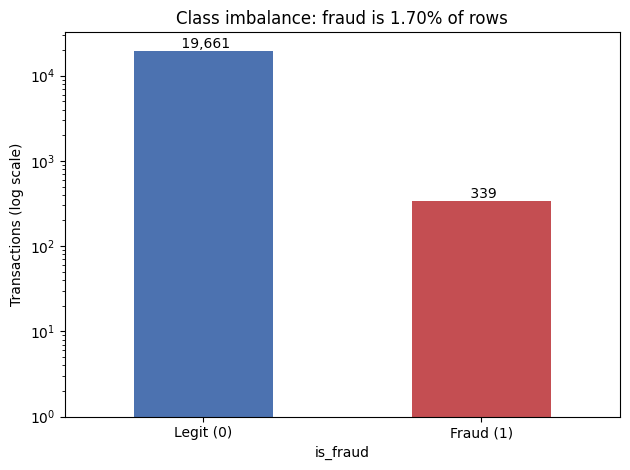

In [13]:
rate = df['is_fraud'].mean()
print(f'Fraud rate: {rate*100:.2f}%  ({df.is_fraud.sum()} of {len(df)})')
print(
    f'Accuracy of a "never fraud" model: {(1-rate)*100:.2f}%  <-- catches ZERO fraud')

counts = df['is_fraud'].value_counts().sort_index()
ax = counts.plot(kind='bar', color=['#4C72B0', '#C44E52'], log=True)
ax.set_xticklabels(['Legit (0)', 'Fraud (1)'], rotation=0)
ax.set_ylabel('Transactions (log scale)')
ax.set_title(f'Class imbalance: fraud is {rate*100:.2f}% of rows')
for i, v in enumerate(counts):
    ax.text(i, v, f' {v:,}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

Test Train split

In [33]:
from sklearn.model_selection import train_test_split

# 1. Separate your features (X) and target variable (y)
# Drop non-feature columns like 'transaction_id' and the target 'is_fraud'
X = df.drop(columns=['transaction_id', 'is_fraud'])
y = df['is_fraud']

# 2. Perform the train-test split (e.g., 80% training, 20% testing)
# stratify=y preserves the class distribution of fraud cases in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"Fraud cases in y_train: {y_train.sum()} ({y_train.mean():.2%})")
print(f"Fraud cases in y_test: {y_test.sum()} ({y_test.mean():.2%})")

Training set shape: (16000, 24)
Testing set shape: (4000, 24)
Fraud cases in y_train: 271 (1.69%)
Fraud cases in y_test: 68 (1.70%)


Encoding variables

In [59]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# 1. Automatically identify column types from X_train
# Boolean columns and categorical columns
bool_cols = X_train.select_dtypes(include=['bool']).columns.tolist()
cat_cols = X_train.select_dtypes(
    include=['object', 'category']).columns.tolist()
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"Numerical columns: {num_cols}")
print(f"Boolean columns: {bool_cols}")
print(f"Categorical columns: {cat_cols}")

# 2. Build the preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        # Convert booleans to integers (0 and 1)
        ('bool', 'passthrough', bool_cols),
        # One-hot encode categorical columns, ignoring unseen categories in test set
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ],
    remainder='passthrough'  # Keeps numerical columns as they are
)

# 3. Fit on training data and transform both train and test data
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

C:\Users\Ruby\AppData\Local\Temp\ipykernel_15180\2168150070.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(


Numerical columns: ['amount_usd', 'is_foreign_transaction', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'ip_country_mismatch', 'billing_shipping_mismatch', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'is_ai_generated_scam_attempt', 'merchant_risk_score', 'prior_disputes']
Boolean columns: ['is_new_merchant', 'used_vpn']
Categorical columns: ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']


In [88]:
df_encoded.head()

,transaction_id,amount_usd,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,is_new_merchant,...,channel_In-App,channel_Online,channel_POS,device_type_Android Phone,device_type_Mac,device_type_POS Terminal,device_type_Smart Watch,device_type_Tablet,device_type_Windows PC,device_type_iPhone
0,1,42.86,0,13.54,2,22.35,39,25,1080.71,0,...,0,1,0,1,0,0,0,0,0,0
1,2,4.75,0,0.71,2,35.28,47,33,4463.72,1,...,0,1,0,1,0,0,0,0,0,0
2,3,77.18,0,0.35,5,9.82,51,59,366.25,0,...,0,1,0,0,1,0,0,0,0,0
3,4,1.69,0,3.42,6,19.72,48,28,1345.29,1,...,0,0,1,1,0,0,0,0,0,0
4,5,261.68,0,2.43,2,17.68,43,36,4192.59,0,...,1,0,0,0,0,0,0,0,0,1


Model Fitting

Random Forest

In [61]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# 1. Initialize the Random Forest with class penalties
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',          # Handles the class imbalance automatically
    random_state=42,
    n_jobs=-1                         # Uses all available CPU cores for faster training
)

# 2. Fit the model on your encoded training data
rf_model.fit(X_train_encoded, y_train)

# 3. Make predictions on the test set
y_pred = rf_model.predict(X_test_encoded)
# Probability of fraud (class 1)
y_prob = rf_model.predict_proba(X_test_encoded)[:, 1]

# 4. Evaluate performance
print("Classification Report:")
print(classification_report(y_test, y_pred))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      3932
           1       0.00      0.00      0.00        68

    accuracy                           0.98      4000
   macro avg       0.49      0.50      0.50      4000
weighted avg       0.97      0.98      0.97      4000

ROC-AUC Score: 0.9056


In [62]:
import numpy as np
from sklearn.metrics import precision_recall_curve, classification_report

# 1. Get the predicted probabilities for fraud (Class 1)
# (If you are using the pipeline, use: y_prob = fraud_pipeline.predict_proba(X_test)[:, 1])
y_prob = rf_model.predict_proba(X_test_encoded)[:, 1]

# 2. Calculate precision, recall, and thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)

# 3. Find the threshold that maximizes the F1-score
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f"Optimal Decision Threshold: {best_threshold:.4f}")

# 4. Apply the new threshold to make predictions
y_pred_custom = (y_prob >= best_threshold).astype(int)

# 5. Evaluate with the new threshold
print("\nClassification Report with Optimized Threshold:")
print(classification_report(y_test, y_pred_custom))

Optimal Decision Threshold: 0.2100

Classification Report with Optimized Threshold:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      3932
           1       0.25      0.29      0.27        68

    accuracy                           0.97      4000
   macro avg       0.62      0.64      0.63      4000
weighted avg       0.98      0.97      0.97      4000



--- Random Forest Top 10 Feature Importances ---


,Feature,Importance
0,merchant_risk_score,0.117171
1,cvv_retry_count,0.104328
2,velocity_score,0.084102
3,ip_country_mismatch,0.062416
4,hours_since_last_txn,0.047297
5,auth_method_No Authentication,0.042522
6,amount_usd,0.039926
7,account_balance_usd,0.037790
8,time_of_day_hour,0.037026
9,distance_from_home_km,0.036244


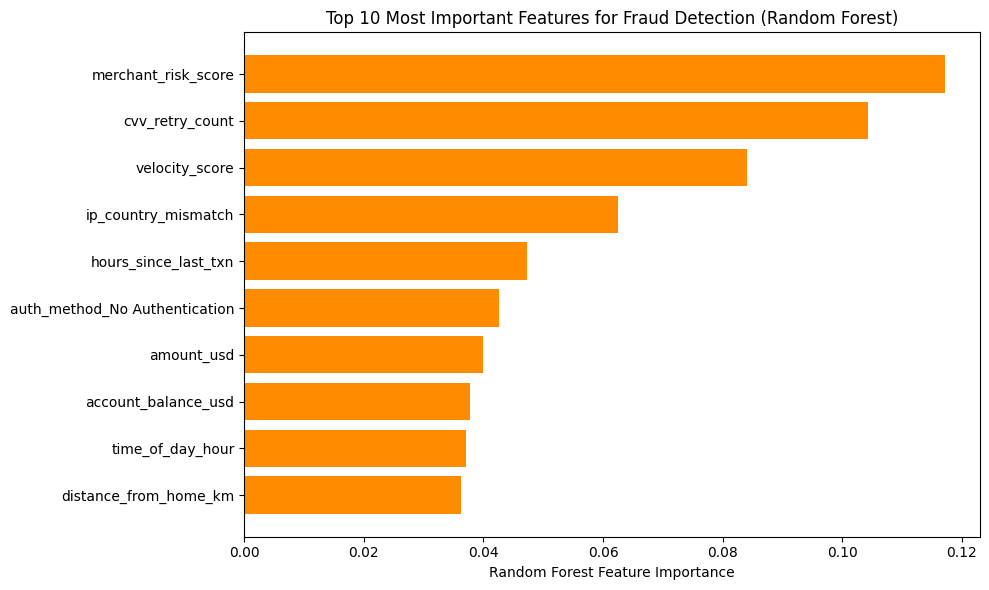

In [69]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Get feature names from the preprocessor & importances
feature_names = preprocessor.get_feature_names_out()
importances = rf_model.feature_importances_

# 2. Create a dataframe and clean up names
rf_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

rf_imp_df['Feature'] = rf_imp_df['Feature'].str.replace(
    r'^(cat__|bool__|remainder__)', '', regex=True)

# 3. Display the top 10 as a table
print("--- Random Forest Top 10 Feature Importances ---")
display(rf_imp_df.head(10))

# 4. Plot top 10
plt.figure(figsize=(10, 6))
top_rf = rf_imp_df.head(10)
plt.barh(top_rf['Feature'][::-1], top_rf['Importance']
         [::-1], color='darkorange')
plt.xlabel("Random Forest Feature Importance")
plt.title("Top 10 Most Important Features for Fraud Detection (Random Forest)")
plt.tight_layout()
plt.show()

XGBoost

In [64]:
import numpy as np
from xgboost import XGBClassifier
from sklearn.metrics import precision_recall_curve, classification_report, roc_auc_score

# 1. Calculate scale_pos_weight for class imbalance
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight_val = neg_count / pos_count

# 2. Initialize and train XGBoost
xgb_model = XGBClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=5,
    scale_pos_weight=scale_pos_weight_val,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_encoded, y_train)

# 3. Predict probabilities on test set
y_prob_xgb = xgb_model.predict_proba(X_test_encoded)[:, 1]
print(f"XGBoost ROC-AUC Score: {roc_auc_score(y_test, y_prob_xgb):.4f}")

# 4. Find the optimal decision threshold maximizing F1-score
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_xgb)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold_xgb = thresholds[best_idx]

print(f"Optimal XGBoost Decision Threshold: {best_threshold_xgb:.4f}")

# 5. Apply threshold and print classification report
y_pred_xgb_custom = (y_prob_xgb >= best_threshold_xgb).astype(int)

print("\nXGBoost Classification Report with Optimized Threshold:")
print(classification_report(y_test, y_pred_xgb_custom))

XGBoost ROC-AUC Score: 0.8820
Optimal XGBoost Decision Threshold: 0.6598

XGBoost Classification Report with Optimized Threshold:
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      3932
           1       0.23      0.32      0.27        68

    accuracy                           0.97      4000
   macro avg       0.61      0.65      0.63      4000
weighted avg       0.98      0.97      0.97      4000



--- XGBoost Top 10 Feature Importances ---


,Feature,Importance
0,cvv_retry_count,0.101357
1,ip_country_mismatch,0.078717
2,auth_method_No Authentication,0.058097
3,is_new_merchant,0.053999
4,billing_shipping_mismatch,0.053160
5,is_foreign_transaction,0.043862
6,merchant_risk_score,0.039960
7,used_vpn,0.035952
8,velocity_score,0.028953
9,is_ai_generated_scam_attempt,0.026644


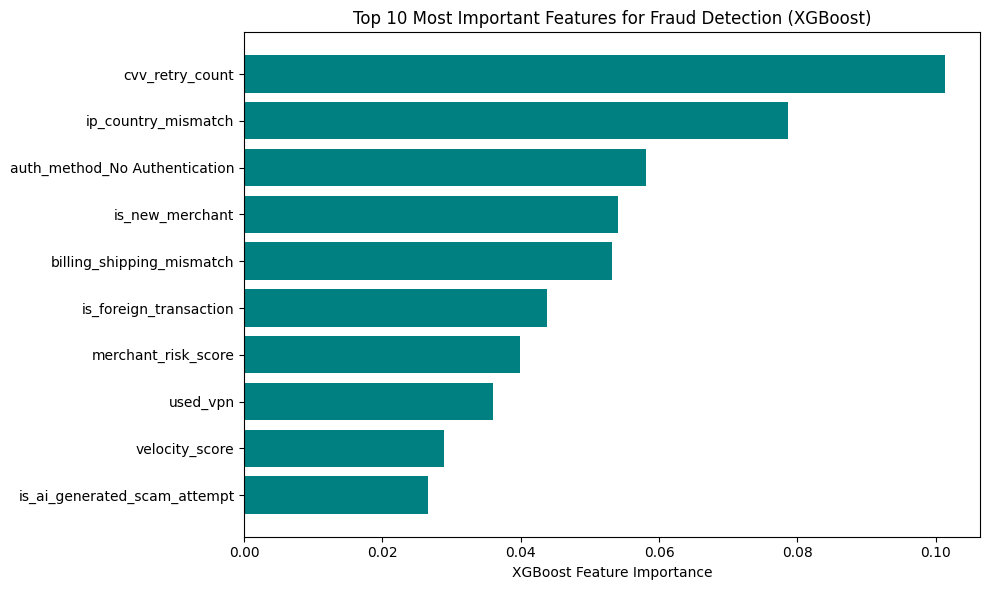

In [68]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Get feature names from the preprocessor & importances
feature_names = preprocessor.get_feature_names_out()
importances = xgb_model.feature_importances_

# 2. Create a dataframe and clean up names
xgb_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

xgb_imp_df['Feature'] = xgb_imp_df['Feature'].str.replace(
    r'^(cat__|bool__|remainder__)', '', regex=True)

# 3. Display the top 10 as a table
print("--- XGBoost Top 10 Feature Importances ---")
display(xgb_imp_df.head(10))

# 4. Plot top 10
plt.figure(figsize=(10, 6))
top_xgb = xgb_imp_df.head(10)
plt.barh(top_xgb['Feature'][::-1], top_xgb['Importance'][::-1], color='teal')
plt.xlabel("XGBoost Feature Importance")
plt.title("Top 10 Most Important Features for Fraud Detection (XGBoost)")
plt.tight_layout()
plt.show()

Decision tree

Decision Tree ROC-AUC Score: 0.5378
Optimal Decision Tree Threshold: 1.0000

Decision Tree Classification Report with Optimized Threshold:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      3932
           1       0.11      0.09      0.10        68

    accuracy                           0.97      4000
   macro avg       0.55      0.54      0.54      4000
weighted avg       0.97      0.97      0.97      4000


--- Decision Tree Top 10 Feature Importances ---


,Feature,Importance
0,cvv_retry_count,0.165347
1,merchant_risk_score,0.146090
2,ip_country_mismatch,0.103311
3,velocity_score,0.088032
4,hours_since_last_txn,0.052857
5,card_age_months,0.043130
6,amount_usd,0.039467
7,distance_from_home_km,0.038331
8,time_of_day_hour,0.035622
9,auth_method_No Authentication,0.035541


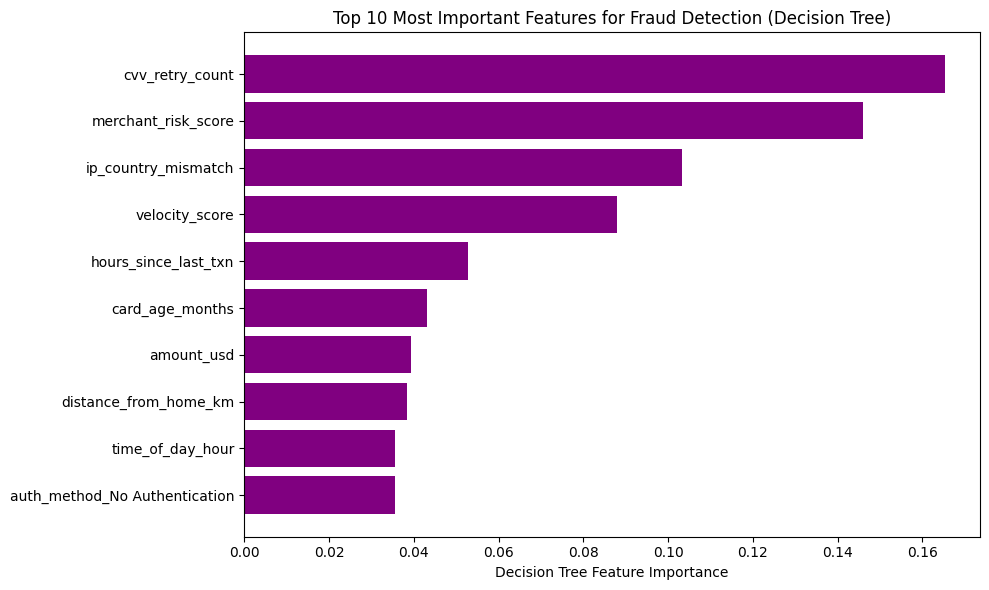

In [70]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_recall_curve, classification_report, roc_auc_score

# 1. Initialize and train Decision Tree with class penalties
dt_model = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)

dt_model.fit(X_train_encoded, y_train)

# 2. Predict probabilities on test set
y_prob_dt = dt_model.predict_proba(X_test_encoded)[:, 1]
print(f"Decision Tree ROC-AUC Score: {roc_auc_score(y_test, y_prob_dt):.4f}")

# 3. Find the optimal decision threshold maximizing F1-score
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_dt)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold_dt = thresholds[best_idx]

print(f"Optimal Decision Tree Threshold: {best_threshold_dt:.4f}")

# 4. Apply threshold and print classification report
y_pred_dt_custom = (y_prob_dt >= best_threshold_dt).astype(int)

print("\nDecision Tree Classification Report with Optimized Threshold:")
print(classification_report(y_test, y_pred_dt_custom))

# 5. Feature Importances (Table + Plot)
feature_names = preprocessor.get_feature_names_out()
importances = dt_model.feature_importances_

dt_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

# Clean up prefixes
dt_imp_df['Feature'] = dt_imp_df['Feature'].str.replace(
    r'^(cat__|bool__|remainder__)', '', regex=True)

# Display table
print("\n--- Decision Tree Top 10 Feature Importances ---")
display(dt_imp_df.head(10))

# Plot top 10
plt.figure(figsize=(10, 6))
top_dt = dt_imp_df.head(10)
plt.barh(top_dt['Feature'][::-1], top_dt['Importance'][::-1], color='purple')
plt.xlabel("Decision Tree Feature Importance")
plt.title("Top 10 Most Important Features for Fraud Detection (Decision Tree)")
plt.tight_layout()
plt.show()

In [72]:
pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   -------- ------------------------------- 0.3/1.4 MB 8.9 MB/s eta 0:00:01
   ----------------- ---------------------- 0.6/1.4 MB 7.6 MB/s eta 0:00:01
   ----------------------------- ---------- 1.0/1.4 MB 7.9 MB/s eta 0:00:01
   ---------------------------------------  1.4/1.4 MB 7.8 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 7.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


LightGBM

LightGBM ROC-AUC Score: 0.8953
Optimal LightGBM Decision Threshold: 0.6793

LightGBM Classification Report with Optimized Threshold:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      3932
           1       0.25      0.35      0.29        68

    accuracy                           0.97      4000
   macro avg       0.62      0.67      0.64      4000
weighted avg       0.98      0.97      0.97      4000


--- LightGBM Top 10 Feature Importances ---


,Feature,Importance
0,merchant_risk_score,528
1,velocity_score,480
2,amount_usd,245
3,account_balance_usd,241
4,cvv_retry_count,239
5,time_of_day_hour,212
6,distance_from_home_km,199
7,hours_since_last_txn,194
8,customer_age,164
9,ip_country_mismatch,150


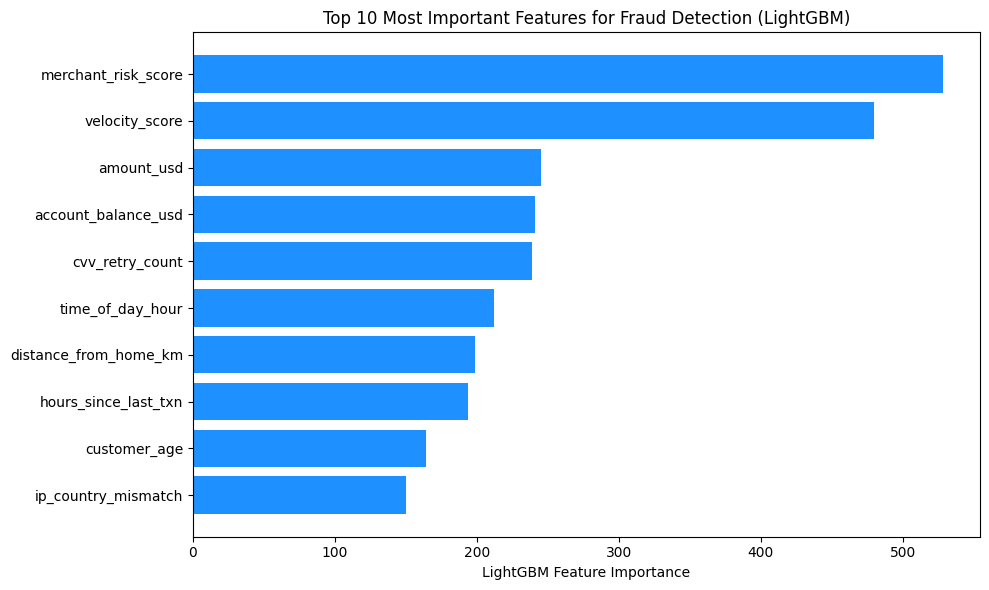

In [73]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.metrics import precision_recall_curve, classification_report, roc_auc_score

# 1. Initialize and train LightGBM with class balancing
lgb_model = LGBMClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=5,
    class_weight='balanced',  # Automatically handles class imbalance
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

lgb_model.fit(X_train_encoded, y_train)

# 2. Predict probabilities on test set
y_prob_lgb = lgb_model.predict_proba(X_test_encoded)[:, 1]
print(f"LightGBM ROC-AUC Score: {roc_auc_score(y_test, y_prob_lgb):.4f}")

# 3. Find the optimal decision threshold maximizing F1-score
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_lgb)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold_lgb = thresholds[best_idx]

print(f"Optimal LightGBM Decision Threshold: {best_threshold_lgb:.4f}")

# 4. Apply threshold and print classification report
y_pred_lgb_custom = (y_prob_lgb >= best_threshold_lgb).astype(int)

print("\nLightGBM Classification Report with Optimized Threshold:")
print(classification_report(y_test, y_pred_lgb_custom))

# 5. Feature Importances (Table + Plot)
feature_names = preprocessor.get_feature_names_out()
importances = lgb_model.feature_importances_

lgb_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

# Clean up prefixes
lgb_imp_df['Feature'] = lgb_imp_df['Feature'].str.replace(
    r'^(cat__|bool__|remainder__)', '', regex=True)

# Display table
print("\n--- LightGBM Top 10 Feature Importances ---")
display(lgb_imp_df.head(10))

# Plot top 10
plt.figure(figsize=(10, 6))
top_lgb = lgb_imp_df.head(10)
plt.barh(top_lgb['Feature'][::-1], top_lgb['Importance']
         [::-1], color='dodgerblue')
plt.xlabel("LightGBM Feature Importance")
plt.title("Top 10 Most Important Features for Fraud Detection (LightGBM)")
plt.tight_layout()
plt.show()

summary

In [74]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_recall_fscore_support

# Define the dictionary of your trained models
# (If you used the regularized pruned decision tree, replace dt_model with dt_pruned)
models = {
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'LightGBM': lgb_model,
    'Decision Tree': dt_model
}

results = []

for name, model in models.items():
    # 1. Get predicted probabilities for the positive (fraud) class
    y_prob = model.predict_proba(X_test_encoded)[:, 1]

    # 2. Calculate ROC-AUC
    roc_auc = roc_auc_score(y_test, y_prob)

    # 3. Find optimal decision threshold maximizing F1-score
    precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(
        thresholds) else 0.5

    # 4. Apply the optimal threshold
    y_pred = (y_prob >= best_threshold).astype(int)

    # 5. Extract metrics for Class 1 (Fraud)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average=None, zero_division=0)

    fraud_precision = precision[1] if len(precision) > 1 else 0.0
    fraud_recall = recall[1] if len(recall) > 1 else 0.0
    fraud_f1 = f1[1] if len(f1) > 1 else 0.0

    # Store results
    results.append({
        'Model': name,
        'ROC-AUC': round(roc_auc, 4),
        'Opt Threshold': round(best_threshold, 4),
        'Fraud Precision': round(fraud_precision, 4),
        'Fraud Recall': round(fraud_recall, 4),
        'Fraud F1-Score': round(fraud_f1, 4)
    })

# Convert to DataFrame and sort by ROC-AUC
summary_df = pd.DataFrame(results).sort_values(
    by='ROC-AUC', ascending=False).reset_index(drop=True)

# Display the summary comparison table
print("--- Model Performance Comparison Summary ---")
display(summary_df)

--- Model Performance Comparison Summary ---


,Model,ROC-AUC,Opt Threshold,Fraud Precision,Fraud Recall,Fraud F1-Score
0,Random Forest,0.9056,0.2100,0.2469,0.2941,0.2685
1,LightGBM,0.8953,0.6793,0.2474,0.3529,0.2909
2,XGBoost,0.8820,0.6598,0.2292,0.3235,0.2683
3,Decision Tree,0.5378,1.0000,0.1071,0.0882,0.0968


Ensemble Voting

In [76]:
import numpy as np
from sklearn.metrics import precision_recall_curve, classification_report, roc_auc_score

# 1. Get probabilities from each trained model
y_prob_rf = rf_model.predict_proba(X_test_encoded)[:, 1]
y_prob_xgb = xgb_model.predict_proba(X_test_encoded)[:, 1]
y_prob_lgb = lgb_model.predict_proba(X_test_encoded)[:, 1]

# 2. Average them together for soft voting
y_prob_voting = (y_prob_rf + y_prob_xgb + y_prob_lgb) / 3

# 3. Print ROC-AUC Score
print(
    f"Ensemble Voting ROC-AUC Score: {roc_auc_score(y_test, y_prob_voting):.4f}")

# 4. Find the optimal decision threshold maximizing F1-score
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_voting)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold_voting = thresholds[best_idx] if best_idx < len(
    thresholds) else 0.5

print(f"Optimal Voting Decision Threshold: {best_threshold_voting:.4f}")

# 5. Apply the threshold and print the classification report
y_pred_voting_custom = (y_prob_voting >= best_threshold_voting).astype(int)

print("\nEnsemble Voting Classification Report with Optimized Threshold:")
print(classification_report(y_test, y_pred_voting_custom))

Ensemble Voting ROC-AUC Score: 0.9003
Optimal Voting Decision Threshold: 0.5146

Ensemble Voting Classification Report with Optimized Threshold:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      3932
           1       0.26      0.32      0.29        68

    accuracy                           0.97      4000
   macro avg       0.62      0.65      0.64      4000
weighted avg       0.98      0.97      0.97      4000



summary

In [77]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_recall_fscore_support

# 1. Calculate ensemble probabilities
y_prob_rf = rf_model.predict_proba(X_test_encoded)[:, 1]
y_prob_xgb = xgb_model.predict_proba(X_test_encoded)[:, 1]
y_prob_lgb = lgb_model.predict_proba(X_test_encoded)[:, 1]
y_prob_voting = (y_prob_rf + y_prob_xgb + y_prob_lgb) / 3

# Define all models including the ensemble
models = {
    'Random Forest': rf_model.predict_proba(X_test_encoded)[:, 1],
    'LightGBM': y_prob_lgb,
    'XGBoost': y_prob_xgb,
    'Ensemble Voting': y_prob_voting,
    'Decision Tree': dt_model.predict_proba(X_test_encoded)[:, 1]
}

results = []

for name, y_prob in models.items():
    # 2. Calculate ROC-AUC
    roc_auc = roc_auc_score(y_test, y_prob)

    # 3. Find optimal decision threshold maximizing F1-score
    precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(
        thresholds) else 0.5

    # 4. Apply the optimal threshold
    y_pred = (y_prob >= best_threshold).astype(int)

    # 5. Extract metrics for Class 1 (Fraud)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average=None, zero_division=0)

    fraud_precision = precision[1] if len(precision) > 1 else 0.0
    fraud_recall = recall[1] if len(recall) > 1 else 0.0
    fraud_f1 = f1[1] if len(f1) > 1 else 0.0

    # Store results
    results.append({
        'Model': name,
        'ROC-AUC': round(roc_auc, 4),
        'Opt Threshold': round(best_threshold, 4),
        'Fraud Precision': round(fraud_precision, 4),
        'Fraud Recall': round(fraud_recall, 4),
        'Fraud F1-Score': round(fraud_f1, 4)
    })

# Convert to DataFrame and sort by ROC-AUC
summary_df = pd.DataFrame(results).sort_values(
    by='ROC-AUC', ascending=False).reset_index(drop=True)

# Display final comparison table
print("--- Final Model Performance Comparison Summary ---")
display(summary_df)

--- Final Model Performance Comparison Summary ---


,Model,ROC-AUC,Opt Threshold,Fraud Precision,Fraud Recall,Fraud F1-Score
0,Random Forest,0.9056,0.2100,0.2469,0.2941,0.2685
1,Ensemble Voting,0.9003,0.5146,0.2588,0.3235,0.2876
2,LightGBM,0.8953,0.6793,0.2474,0.3529,0.2909
3,XGBoost,0.8820,0.6598,0.2292,0.3235,0.2683
4,Decision Tree,0.5378,1.0000,0.1071,0.0882,0.0968


shap

--- Global Feature Impact (SHAP Summary Plot) ---


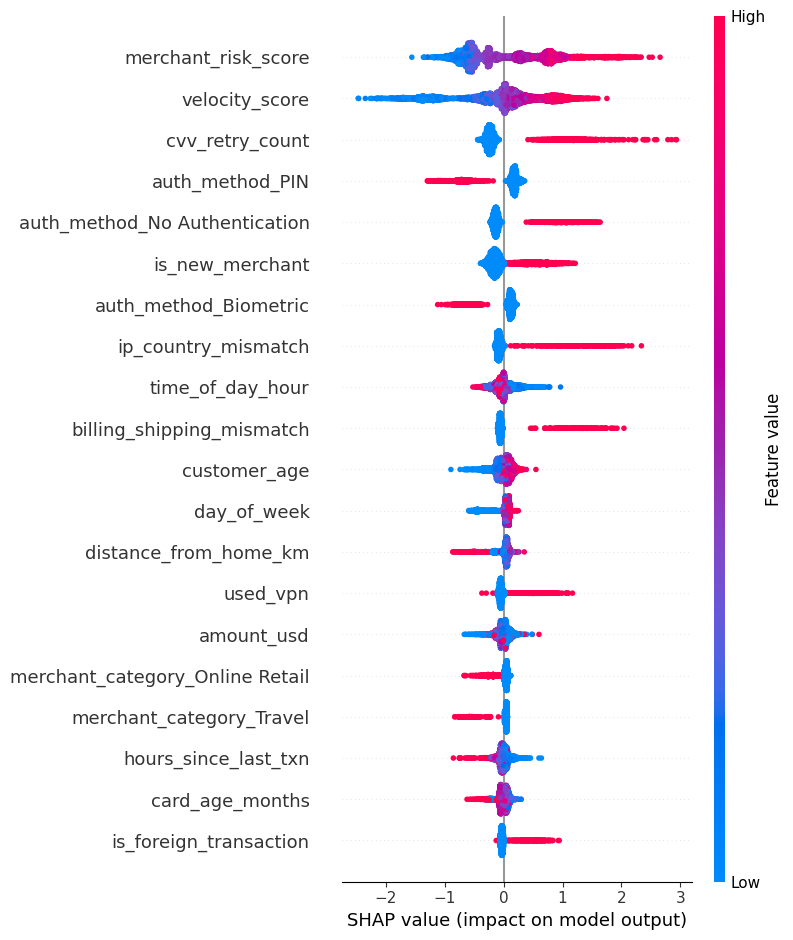


--- Local Explanation for a Single Transaction ---


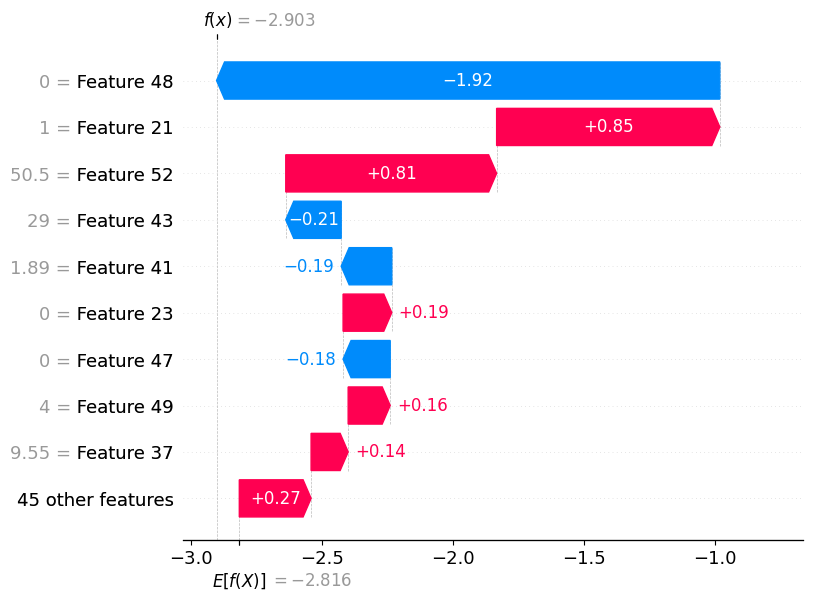

In [78]:
import shap
import pandas as pd

# 1. Initialize the SHAP TreeExplainer for your trained LightGBM model
explainer = shap.TreeExplainer(lgb_model)

# 2. Calculate SHAP values for your test set
# (Note: For binary classifiers, shap_values for LightGBM returns the values for the positive class)
shap_values = explainer(X_test_encoded)

# Clean feature names for clean plotting
feature_names = preprocessor.get_feature_names_out()
feature_names = [f.replace('cat__', '').replace(
    'bool__', '').replace('remainder__', '') for f in feature_names]
X_test_df = pd.DataFrame(X_test_encoded, columns=feature_names)

# 3. Global Summary Plot (Shows overall top features driving fraud predictions)
print("--- Global Feature Impact (SHAP Summary Plot) ---")
shap.summary_plot(shap_values, X_test_df)

# 4. Local Explanation (Explains why a SPECIFIC suspicious transaction was flagged)
# Let's pick the first transaction in your test set
print("\n--- Local Explanation for a Single Transaction ---")
shap.plots.waterfall(shap_values[0])

In [79]:
import pandas as pd
import numpy as np

# 1. Ensure shap_values is extracted (if not already done)
# shap_values = explainer(X_test_encoded)

# 2. Extract the raw SHAP values matrix (handles modern shap.Explanation objects)
shap_matrix = shap_values.values if hasattr(
    shap_values, 'values') else shap_values

# 3. Calculate mean absolute SHAP value for each feature
mean_abs_shap = np.abs(shap_matrix).mean(axis=0)

# 4. Create a clean DataFrame ranking the most important features
shap_importance_df = pd.DataFrame({
    'Feature': X_test_df.columns,
    'Mean Absolute SHAP Value': mean_abs_shap
}).sort_values(by='Mean Absolute SHAP Value', ascending=False).reset_index(drop=True)

# 5. Display the top 10 features
print("--- Top 10 Features Ranked by SHAP Importance ---")
display(shap_importance_df.head(10))

--- Top 10 Features Ranked by SHAP Importance ---


,Feature,Mean Absolute SHAP Value
0,merchant_risk_score,0.633146
1,velocity_score,0.488403
2,cvv_retry_count,0.383343
3,auth_method_PIN,0.293929
4,auth_method_No Authentication,0.242623
5,is_new_merchant,0.237184
6,auth_method_Biometric,0.193864
7,ip_country_mismatch,0.147297
8,time_of_day_hour,0.111799
9,billing_shipping_mismatch,0.105192


The model relies primarily on merchant risk history, transaction velocity, and CVV failure counts to separate fraud from normal behavior."

models based on shap features

In [80]:
import pandas as pd
import numpy as np
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, classification_report, precision_recall_curve

# 1. Define how many top features you want to keep
top_k = 10
selected_features = shap_importance_df['Feature'].head(top_k).tolist()

print(f"Retraining LightGBM using the top {top_k} features:")
print(selected_features)

# 2. Convert encoded arrays back to DataFrames (ensuring column names match)
feature_names = [f.replace('cat__', '').replace('bool__', '').replace(
    'remainder__', '') for f in preprocessor.get_feature_names_out()]
X_train_df = pd.DataFrame(X_train_encoded, columns=feature_names)
X_test_df = pd.DataFrame(X_test_encoded, columns=feature_names)

# 3. Filter datasets to only include the top features
X_train_subset = X_train_df[selected_features]
X_test_subset = X_test_df[selected_features]

# 4. Retrain LightGBM on the feature subset
lgb_subset_model = LGBMClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

lgb_subset_model.fit(X_train_subset, y_train)

# 5. Evaluate performance
y_prob_sub = lgb_subset_model.predict_proba(X_test_subset)[:, 1]
print(f"\nSubset Model ROC-AUC Score: {roc_auc_score(y_test, y_prob_sub):.4f}")

# Find optimal threshold for the subset model
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_sub)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_threshold_sub = thresholds[np.argmax(f1_scores)]

y_pred_sub = (y_prob_sub >= best_threshold_sub).astype(int)
print(f"Optimal Threshold: {best_threshold_sub:.4f}")
print("\nClassification Report (Top Features Only):")
print(classification_report(y_test, y_pred_sub))

Retraining LightGBM using the top 10 features:
['merchant_risk_score', 'velocity_score', 'cvv_retry_count', 'auth_method_PIN', 'auth_method_No Authentication', 'is_new_merchant', 'auth_method_Biometric', 'ip_country_mismatch', 'time_of_day_hour', 'billing_shipping_mismatch']

Subset Model ROC-AUC Score: 0.8912
Optimal Threshold: 0.8281

Classification Report (Top Features Only):
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      3932
           1       0.24      0.28      0.26        68

    accuracy                           0.97      4000
   macro avg       0.62      0.63      0.62      4000
weighted avg       0.97      0.97      0.97      4000



In [81]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_recall_fscore_support

# 1. Full Feature Model Evaluation
y_prob_full = lgb_model.predict_proba(X_test_encoded)[:, 1]
roc_full = roc_auc_score(y_test, y_prob_full)

prec_f, rec_f, thresh_f = precision_recall_curve(y_test, y_prob_full)
f1_f = 2 * (prec_f * rec_f) / (prec_f + rec_f + 1e-10)
best_thresh_f = thresh_f[np.argmax(f1_f)]
y_pred_f = (y_prob_full >= best_thresh_f).astype(int)
p_f, r_f, f_f, _ = precision_recall_fscore_support(
    y_test, y_pred_f, average=None, zero_division=0)

# 2. Subset Feature Model Evaluation (Top Features)
y_prob_sub = lgb_subset_model.predict_proba(X_test_subset)[:, 1]
roc_sub = roc_auc_score(y_test, y_prob_sub)

prec_s, rec_s, thresh_s = precision_recall_curve(y_test, y_prob_sub)
f1_s = 2 * (prec_s * rec_s) / (prec_s + rec_s + 1e-10)
best_thresh_s = thresh_s[np.argmax(f1_s)]
y_pred_s = (y_prob_sub >= best_thresh_s).astype(int)
p_s, r_s, f_s, _ = precision_recall_fscore_support(
    y_test, y_pred_s, average=None, zero_division=0)

# 3. Compile into a Comparative Summary DataFrame
comparison_data = [
    {
        'Model Configuration': f'Full Features (All {X_test_encoded.shape[1]} features)',
        'ROC-AUC': round(roc_full, 4),
        'Opt Threshold': round(best_thresh_f, 4),
        'Fraud Precision': round(p_f[1], 4),
        'Fraud Recall': round(r_f[1], 4),
        'Fraud F1-Score': round(f_f[1], 4)
    },
    {
        'Model Configuration': f'Top-{len(selected_features)} Features (SHAP Selected)',
        'ROC-AUC': round(roc_sub, 4),
        'Opt Threshold': round(best_thresh_s, 4),
        'Fraud Precision': round(p_s[1], 4),
        'Fraud Recall': round(r_s[1], 4),
        'Fraud F1-Score': round(f_s[1], 4)
    }
]

comparison_df = pd.DataFrame(comparison_data)

print("--- Feature Reduction Performance Comparison ---")
display(comparison_df)

--- Feature Reduction Performance Comparison ---


,Model Configuration,ROC-AUC,Opt Threshold,Fraud Precision,Fraud Recall,Fraud F1-Score
0,Full Features (All 54 features),0.8953,0.6793,0.2474,0.3529,0.2909
1,Top-10 Features (SHAP Selected),0.8912,0.8281,0.2436,0.2794,0.2603


In [83]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, precision_recall_curve, classification_report

# 1. Initialize and train Random Forest on the top features subset
rf_subset_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=None,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_subset_model.fit(X_train_subset, y_train)

# 2. Predict probabilities on test subset
y_prob_rf_sub = rf_subset_model.predict_proba(X_test_subset)[:, 1]
print(
    f"Random Forest Subset ROC-AUC Score: {roc_auc_score(y_test, y_prob_rf_sub):.4f}")

# 3. Find optimal decision threshold maximizing F1-score
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_rf_sub)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_threshold_rf_sub = thresholds[np.argmax(f1_scores)]
print(f"Optimal Random Forest Threshold (Subset): {best_threshold_rf_sub:.4f}")

# 4. Apply threshold and print classification report
y_pred_rf_sub = (y_prob_rf_sub >= best_threshold_rf_sub).astype(int)
print("\nRandom Forest Classification Report (Top Features Only):")
print(classification_report(y_test, y_pred_rf_sub))

Random Forest Subset ROC-AUC Score: 0.8530
Optimal Random Forest Threshold (Subset): 0.2933

Random Forest Classification Report (Top Features Only):
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      3932
           1       0.20      0.32      0.25        68

    accuracy                           0.97      4000
   macro avg       0.60      0.65      0.62      4000
weighted avg       0.97      0.97      0.97      4000

--- Random Forest Feature Reduction Comparison ---


,Model Configuration,ROC-AUC,Opt Threshold,Fraud Precision,Fraud Recall,Fraud F1-Score
0,RF - Full Features (All 54 features),0.9056,0.2100,0.2469,0.2941,0.2685
1,RF - Top-10 Features (SHAP Selected),0.8530,0.2933,0.2037,0.3235,0.2500


In [84]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_recall_fscore_support

# 1. Full Feature Random Forest Evaluation
y_prob_rf_full = rf_model.predict_proba(X_test_encoded)[:, 1]
roc_rf_full = roc_auc_score(y_test, y_prob_rf_full)

prec_rf_f, rec_rf_f, thresh_rf_f = precision_recall_curve(
    y_test, y_prob_rf_full)
f1_rf_f = 2 * (prec_rf_f * rec_rf_f) / (prec_rf_f + rec_rf_f + 1e-10)
best_thresh_rf_f = thresh_rf_f[np.argmax(f1_rf_f)]
y_pred_rf_f = (y_prob_rf_full >= best_thresh_rf_f).astype(int)
p_rf_f, r_rf_f, f_rf_f, _ = precision_recall_fscore_support(
    y_test, y_pred_rf_f, average=None, zero_division=0)

# 2. Subset Feature Random Forest Evaluation (Top Features)
y_prob_rf_sub = rf_subset_model.predict_proba(X_test_subset)[:, 1]
roc_rf_sub = roc_auc_score(y_test, y_prob_rf_sub)

prec_rf_s, rec_rf_s, thresh_rf_s = precision_recall_curve(
    y_test, y_prob_rf_sub)
f1_rf_s = 2 * (prec_rf_s * rec_rf_s) / (prec_rf_s + rec_rf_s + 1e-10)
best_thresh_rf_s = thresh_rf_s[np.argmax(f1_rf_s)]
y_pred_rf_s = (y_prob_rf_sub >= best_thresh_rf_s).astype(int)
p_rf_s, r_rf_s, f_rf_s, _ = precision_recall_fscore_support(
    y_test, y_pred_rf_s, average=None, zero_division=0)

# 3. Compile into a Comparative Summary DataFrame for Random Forest
comparison_data_rf = [
    {
        'Model Configuration': f'RF - Full Features (All {X_test_encoded.shape[1]} features)',
        'ROC-AUC': round(roc_rf_full, 4),
        'Opt Threshold': round(best_thresh_rf_f, 4),
        'Fraud Precision': round(p_rf_f[1], 4),
        'Fraud Recall': round(r_rf_f[1], 4),
        'Fraud F1-Score': round(f_rf_f[1], 4)
    },
    {
        'Model Configuration': f'RF - Top-{len(selected_features)} Features (SHAP Selected)',
        'ROC-AUC': round(roc_rf_sub, 4),
        'Opt Threshold': round(best_thresh_rf_s, 4),
        'Fraud Precision': round(p_rf_s[1], 4),
        'Fraud Recall': round(r_rf_s[1], 4),
        'Fraud F1-Score': round(f_rf_s[1], 4)
    }
]

comparison_rf_df = pd.DataFrame(comparison_data_rf)

print("--- Random Forest Feature Reduction Comparison ---")
display(comparison_rf_df)

--- Random Forest Feature Reduction Comparison ---


,Model Configuration,ROC-AUC,Opt Threshold,Fraud Precision,Fraud Recall,Fraud F1-Score
0,RF - Full Features (All 54 features),0.9056,0.2100,0.2469,0.2941,0.2685
1,RF - Top-10 Features (SHAP Selected),0.8530,0.2933,0.2037,0.3235,0.2500


In [85]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_recall_fscore_support, classification_report

# 1. Initialize and train Decision Tree on the top features subset
dt_subset_model = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)

dt_subset_model.fit(X_train_subset, y_train)

# 2. Predict probabilities on test subset
y_prob_dt_sub = dt_subset_model.predict_proba(X_test_subset)[:, 1]
print(
    f"Decision Tree Subset ROC-AUC Score: {roc_auc_score(y_test, y_prob_dt_sub):.4f}")

# 3. Find optimal decision threshold maximizing F1-score
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_dt_sub)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_threshold_dt_sub = thresholds[np.argmax(
    f1_scores)] if len(thresholds) > 0 else 0.5
print(f"Optimal Decision Tree Threshold (Subset): {best_threshold_dt_sub:.4f}")

# 4. Apply threshold and print classification report
y_pred_dt_sub = (y_prob_dt_sub >= best_threshold_dt_sub).astype(int)
print("\nDecision Tree Classification Report (Top Features Only):")
print(classification_report(y_test, y_pred_dt_sub))

# --- 5. Comparative Evaluation (Full Features vs. Subset Features) ---
y_prob_dt_full = dt_model.predict_proba(X_test_encoded)[:, 1]
roc_dt_full = roc_auc_score(y_test, y_prob_dt_full)

prec_dt_f, rec_dt_f, thresh_dt_f = precision_recall_curve(
    y_test, y_prob_dt_full)
f1_dt_f = 2 * (prec_dt_f * rec_dt_f) / (prec_dt_f + rec_dt_f + 1e-10)
best_thresh_dt_f = thresh_dt_f[np.argmax(
    f1_dt_f)] if len(thresh_dt_f) > 0 else 0.5
y_pred_dt_f = (y_prob_dt_full >= best_thresh_dt_f).astype(int)
p_dt_f, r_dt_f, f_dt_f, _ = precision_recall_fscore_support(
    y_test, y_pred_dt_f, average=None, zero_division=0)

roc_dt_sub = roc_auc_score(y_test, y_prob_dt_sub)
p_dt_s, r_dt_s, f_dt_s, _ = precision_recall_fscore_support(
    y_test, y_pred_dt_sub, average=None, zero_division=0)

comparison_data_dt = [
    {
        'Model Configuration': f'DT - Full Features (All {X_test_encoded.shape[1]} features)',
        'ROC-AUC': round(roc_dt_full, 4),
        'Opt Threshold': round(best_thresh_dt_f, 4),
        'Fraud Precision': round(p_dt_f[1], 4) if len(p_dt_f) > 1 else 0.0,
        'Fraud Recall': round(r_dt_f[1], 4) if len(r_dt_f) > 1 else 0.0,
        'Fraud F1-Score': round(f_dt_f[1], 4) if len(f_dt_f) > 1 else 0.0
    },
    {
        'Model Configuration': f'DT - Top-{len(selected_features)} Features (SHAP Selected)',
        'ROC-AUC': round(roc_dt_sub, 4),
        'Opt Threshold': round(best_threshold_dt_sub, 4),
        'Fraud Precision': round(p_dt_s[1], 4) if len(p_dt_s) > 1 else 0.0,
        'Fraud Recall': round(r_dt_s[1], 4) if len(r_dt_s) > 1 else 0.0,
        'Fraud F1-Score': round(f_dt_s[1], 4) if len(f_dt_s) > 1 else 0.0
    }
]

comparison_dt_df = pd.DataFrame(comparison_data_dt)

print("\n--- Decision Tree Feature Reduction Comparison ---")
display(comparison_dt_df)

Decision Tree Subset ROC-AUC Score: 0.5605
Optimal Decision Tree Threshold (Subset): 1.0000

Decision Tree Classification Report (Top Features Only):
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3932
           1       0.17      0.13      0.15        68

    accuracy                           0.97      4000
   macro avg       0.58      0.56      0.57      4000
weighted avg       0.97      0.97      0.97      4000


--- Decision Tree Feature Reduction Comparison ---


,Model Configuration,ROC-AUC,Opt Threshold,Fraud Precision,Fraud Recall,Fraud F1-Score
0,DT - Full Features (All 54 features),0.5378,1.0,0.1071,0.0882,0.0968
1,DT - Top-10 Features (SHAP Selected),0.5605,1.0,0.1667,0.1324,0.1475


In [86]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_recall_fscore_support, classification_report

# 1. Train XGBoost on the subset features (if not already trained)
xgb_subset_model = XGBClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=5,
    scale_pos_weight=98,  # accounting for 98% non-fraud imbalance
    random_state=42,
    n_jobs=-1
)
xgb_subset_model.fit(X_train_subset, y_train)

# 2. Get subset probabilities from all three ensemble members
y_prob_rf_sub = rf_subset_model.predict_proba(X_test_subset)[:, 1]
y_prob_xgb_sub = xgb_subset_model.predict_proba(X_test_subset)[:, 1]
y_prob_lgb_sub = lgb_subset_model.predict_proba(X_test_subset)[:, 1]

# 3. Average them for the Subset Voting Ensemble
y_prob_voting_sub = (y_prob_rf_sub + y_prob_xgb_sub + y_prob_lgb_sub) / 3

# 4. Evaluate Subset Voting Ensemble
roc_voting_sub = roc_auc_score(y_test, y_prob_voting_sub)
prec_v_s, rec_v_s, thresh_v_s = precision_recall_curve(
    y_test, y_prob_voting_sub)
f1_v_s = 2 * (prec_v_s * rec_v_s) / (prec_v_s + rec_v_s + 1e-10)
best_thresh_voting_sub = thresh_v_s[np.argmax(
    f1_v_s)] if len(thresh_v_s) > 0 else 0.5

y_pred_voting_sub = (y_prob_voting_sub >= best_thresh_voting_sub).astype(int)
p_v_s, r_v_s, f_v_s, _ = precision_recall_fscore_support(
    y_test, y_pred_voting_sub, average=None, zero_division=0)

print(f"Ensemble Voting Subset ROC-AUC Score: {roc_voting_sub:.4f}")
print(f"Optimal Voting Threshold (Subset): {best_thresh_voting_sub:.4f}")
print("\nClassification Report (Ensemble Voting - Top Features Only):")
print(classification_report(y_test, y_pred_voting_sub))

# --- 5. Comparative Evaluation (Full Features vs. Subset Features) ---
y_prob_voting_full = (
    rf_model.predict_proba(X_test_encoded)[:, 1] +
    xgb_model.predict_proba(X_test_encoded)[:, 1] +
    lgb_model.predict_proba(X_test_encoded)[:, 1]
) / 3

roc_voting_full = roc_auc_score(y_test, y_prob_voting_full)
prec_v_f, rec_v_f, thresh_v_f = precision_recall_curve(
    y_test, y_prob_voting_full)
f1_v_f = 2 * (prec_v_f * rec_v_f) / (prec_v_f + rec_v_f + 1e-10)
best_thresh_voting_full = thresh_v_f[np.argmax(
    f1_v_f)] if len(thresh_v_f) > 0 else 0.5

y_pred_voting_full = (y_prob_voting_full >=
                      best_thresh_voting_full).astype(int)
p_v_f, r_v_f, f_v_f, _ = precision_recall_fscore_support(
    y_test, y_pred_voting_full, average=None, zero_division=0)

comparison_data_voting = [
    {
        'Model Configuration': f'Ensemble - Full Features (All {X_test_encoded.shape[1]} features)',
        'ROC-AUC': round(roc_voting_full, 4),
        'Opt Threshold': round(best_thresh_voting_full, 4),
        'Fraud Precision': round(p_v_f[1], 4) if len(p_v_f) > 1 else 0.0,
        'Fraud Recall': round(r_v_f[1], 4) if len(r_v_f) > 1 else 0.0,
        'Fraud F1-Score': round(f_v_f[1], 4) if len(f_v_f) > 1 else 0.0
    },
    {
        'Model Configuration': f'Ensemble - Top-{len(selected_features)} Features (SHAP Selected)',
        'ROC-AUC': round(roc_voting_sub, 4),
        'Opt Threshold': round(best_thresh_voting_sub, 4),
        'Fraud Precision': round(p_v_s[1], 4) if len(p_v_s) > 1 else 0.0,
        'Fraud Recall': round(r_v_s[1], 4) if len(r_v_s) > 1 else 0.0,
        'Fraud F1-Score': round(f_v_s[1], 4) if len(f_v_s) > 1 else 0.0
    }
]

comparison_voting_df = pd.DataFrame(comparison_data_voting)

print("\n--- Ensemble Voting Feature Reduction Comparison ---")
display(comparison_voting_df)

Ensemble Voting Subset ROC-AUC Score: 0.8909
Optimal Voting Threshold (Subset): 0.6716

Classification Report (Ensemble Voting - Top Features Only):
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3932
           1       0.28      0.28      0.28        68

    accuracy                           0.98      4000
   macro avg       0.63      0.63      0.63      4000
weighted avg       0.98      0.98      0.98      4000


--- Ensemble Voting Feature Reduction Comparison ---


,Model Configuration,ROC-AUC,Opt Threshold,Fraud Precision,Fraud Recall,Fraud F1-Score
0,Ensemble - Full Features (All 54 features),0.9003,0.5146,0.2588,0.3235,0.2876
1,Ensemble - Top-10 Features (SHAP Selected),0.8909,0.6716,0.2754,0.2794,0.2774


In [87]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_recall_fscore_support

# Define all probability dictionaries for full vs subset models
evaluation_dict = {
    # --- Full Feature Models ---
    'Random Forest (Full)': rf_model.predict_proba(X_test_encoded)[:, 1],
    'LightGBM (Full)': lgb_model.predict_proba(X_test_encoded)[:, 1],
    'XGBoost (Full)': xgb_model.predict_proba(X_test_encoded)[:, 1],
    'Decision Tree (Full)': dt_model.predict_proba(X_test_encoded)[:, 1],
    'Ensemble Voting (Full)': (
        rf_model.predict_proba(X_test_encoded)[:, 1] +
        xgb_model.predict_proba(X_test_encoded)[:, 1] +
        lgb_model.predict_proba(X_test_encoded)[:, 1]
    ) / 3,

    # --- Top SHAP Feature Subset Models ---
    'Random Forest (Top SHAP)': rf_subset_model.predict_proba(X_test_subset)[:, 1],
    'LightGBM (Top SHAP)': lgb_subset_model.predict_proba(X_test_subset)[:, 1],
    'XGBoost (Top SHAP)': xgb_subset_model.predict_proba(X_test_subset)[:, 1],
    'Decision Tree (Top SHAP)': dt_subset_model.predict_proba(X_test_subset)[:, 1],
    'Ensemble Voting (Top SHAP)': (
        rf_subset_model.predict_proba(X_test_subset)[:, 1] +
        xgb_subset_model.predict_proba(X_test_subset)[:, 1] +
        lgb_subset_model.predict_proba(X_test_subset)[:, 1]
    ) / 3
}

results = []

for name, y_prob in evaluation_dict.items():
    # 1. Calculate ROC-AUC
    roc_auc = roc_auc_score(y_test, y_prob)

    # 2. Find optimal decision threshold maximizing F1-score
    precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(
        thresholds) else 0.5

    # 3. Apply threshold
    y_pred = (y_prob >= best_threshold).astype(int)

    # 4. Extract metrics for Class 1 (Fraud)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average=None, zero_division=0)

    fraud_precision = precision[1] if len(precision) > 1 else 0.0
    fraud_recall = recall[1] if len(recall) > 1 else 0.0
    fraud_f1 = f1[1] if len(f1) > 1 else 0.0

    # Store results
    results.append({
        'Model Configuration': name,
        'ROC-AUC': round(roc_auc, 4),
        'Opt Threshold': round(best_threshold, 4),
        'Fraud Precision': round(fraud_precision, 4),
        'Fraud Recall': round(fraud_recall, 4),
        'Fraud F1-Score': round(fraud_f1, 4)
    })

# Convert to DataFrame and sort by Fraud Recall (descending)
master_summary_df = pd.DataFrame(results).sort_values(
    by=['Fraud Recall', 'ROC-AUC'], ascending=False).reset_index(drop=True)

print("--- Master Model Performance Comparison: Full vs. SHAP Features ---")
display(master_summary_df)

--- Master Model Performance Comparison: Full vs. SHAP Features ---


,Model Configuration,ROC-AUC,Opt Threshold,Fraud Precision,Fraud Recall,Fraud F1-Score
0,LightGBM (Full),0.8953,0.6793,0.2474,0.3529,0.2909
1,Ensemble Voting (Full),0.9003,0.5146,0.2588,0.3235,0.2876
2,XGBoost (Full),0.8820,0.6598,0.2292,0.3235,0.2683
3,XGBoost (Top SHAP),0.8787,0.8433,0.2157,0.3235,0.2588
4,Random Forest (Top SHAP),0.8530,0.2933,0.2037,0.3235,0.2500
5,Random Forest (Full),0.9056,0.2100,0.2469,0.2941,0.2685
6,LightGBM (Top SHAP),0.8912,0.8281,0.2436,0.2794,0.2603
7,Ensemble Voting (Top SHAP),0.8909,0.6716,0.2754,0.2794,0.2774
8,Decision Tree (Top SHAP),0.5605,1.0000,0.1667,0.1324,0.1475
9,Decision Tree (Full),0.5378,1.0000,0.1071,0.0882,0.0968


In [122]:
import pandas as pd
import numpy as np

# 1. Select a random index from the test set
random_idx = np.random.randint(0, len(y_test))

# Extract the actual true label for this transaction
true_label = y_test.iloc[random_idx] if hasattr(
    y_test, 'iloc') else y_test[random_idx]

# Safely extract a single row (preserving 2D shape with 1 sample)
if isinstance(X_test_encoded, np.ndarray):
    x_full_row = X_test_encoded[random_idx:random_idx+1]
else:
    x_full_row = X_test_encoded.iloc[[random_idx]]

x_sub_row = X_test_subset.iloc[[random_idx]]

print(f"🎯 Selected Random Test Transaction Index: {random_idx}")
print(
    f"🔒 True Transaction Status: {'🚨 FRAUD' if true_label == 1 else '✅ NORMAL'}\n")

# 2. Define all models, their corresponding data rows, and their optimal thresholds
inference_models = [
    # Full Feature Models
    {'Name': 'LightGBM (Full)', 'Model': lgb_model,
     'Data': x_full_row, 'Threshold': best_thresh_f},
    {'Name': 'Random Forest (Full)', 'Model': rf_model,
     'Data': x_full_row, 'Threshold': best_thresh_rf_f},
    {'Name': 'XGBoost (Full)', 'Model': xgb_model,
     'Data': x_full_row, 'Threshold': best_thresh_rf_f},
    {'Name': 'Decision Tree (Full)', 'Model': dt_model,
     'Data': x_full_row, 'Threshold': best_thresh_dt_f},
    {'Name': 'Ensemble Voting (Full)', 'Model': None, 'Data': x_full_row,
     'Threshold': best_thresh_voting_full, 'IsEnsemble': True, 'Type': 'Full'},

    # Top SHAP Feature Subset Models
    {'Name': 'LightGBM (Top SHAP)', 'Model': lgb_subset_model,
     'Data': x_sub_row, 'Threshold': best_thresh_s},
    {'Name': 'Random Forest (Top SHAP)', 'Model': rf_subset_model,
     'Data': x_sub_row, 'Threshold': best_threshold_rf_sub},
    {'Name': 'XGBoost (Top SHAP)', 'Model': xgb_subset_model,
     'Data': x_sub_row, 'Threshold': 0.5},
    {'Name': 'Decision Tree (Top SHAP)', 'Model': dt_subset_model,
     'Data': x_sub_row, 'Threshold': best_threshold_dt_sub},
    {'Name': 'Ensemble Voting (Top SHAP)', 'Model': None, 'Data': x_sub_row,
     'Threshold': best_thresh_voting_sub, 'IsEnsemble': True, 'Type': 'Subset'}
]

results = []

for item in inference_models:
    if item.get('IsEnsemble'):
        if item['Type'] == 'Full':
            prob = (
                rf_model.predict_proba(x_full_row)[:, 1] +
                xgb_model.predict_proba(x_full_row)[:, 1] +
                lgb_model.predict_proba(x_full_row)[:, 1]
            )[0] / 3
        else:
            prob = (
                rf_subset_model.predict_proba(x_sub_row)[:, 1] +
                xgb_subset_model.predict_proba(x_sub_row)[:, 1] +
                lgb_subset_model.predict_proba(x_sub_row)[:, 1]
            )[0] / 3
    else:
        prob = item['Model'].predict_proba(item['Data'])[:, 1][0]

    thresh = item['Threshold']
    pred = 1 if prob >= thresh else 0
    correct = (pred == true_label)

    results.append({
        'Model Configuration': item['Name'],
        'Fraud Probability': round(float(prob), 4),
        'Decision Threshold': round(float(thresh), 4),
        'Prediction': 'FRAUD' if pred == 1 else 'NORMAL',
        'Correct?':  'Yes' if correct else 'No'
    })

# 3. Compile and display summary table
prediction_summary_df = pd.DataFrame(results)
display(prediction_summary_df)

🎯 Selected Random Test Transaction Index: 3924
🔒 True Transaction Status: ✅ NORMAL



,Model Configuration,Fraud Probability,Decision Threshold,Prediction,Correct?
0,LightGBM (Full),0.1512,0.6793,NORMAL,Yes
1,Random Forest (Full),0.0000,0.2100,NORMAL,Yes
2,XGBoost (Full),0.1035,0.2100,NORMAL,Yes
3,Decision Tree (Full),0.0000,1.0000,NORMAL,Yes
4,Ensemble Voting (Full),0.0849,0.5146,NORMAL,Yes
5,LightGBM (Top SHAP),0.0481,0.8281,NORMAL,Yes
6,Random Forest (Top SHAP),0.0000,0.2933,NORMAL,Yes
7,XGBoost (Top SHAP),0.0484,0.5000,NORMAL,Yes
8,Decision Tree (Top SHAP),0.0000,1.0000,NORMAL,Yes
9,Ensemble Voting (Top SHAP),0.0322,0.6716,NORMAL,Yes


In [123]:
import pandas as pd
import numpy as np

# 1. Find indices in the test set where the true label is explicitly FRAUD (1)
y_test_array = y_test.to_numpy() if hasattr(
    y_test, 'to_numpy') else np.array(y_test)
fraud_indices = np.where(y_test_array == 1)[0]

if len(fraud_indices) == 0:
    print("No fraud cases found in y_test! Check your test split or class balance.")
else:
    # Pick a random fraud index from the available ones
    random_fraud_idx = np.random.choice(fraud_indices)
    true_label = 1

    # Safely extract a single row for full features and subset features
    if isinstance(X_test_encoded, np.ndarray):
        x_full_row = X_test_encoded[random_fraud_idx:random_fraud_idx+1]
    else:
        x_full_row = X_test_encoded.iloc[[random_fraud_idx]]

    x_sub_row = X_test_subset.iloc[[random_fraud_idx]]

    print(f"Selected Fraud Test Transaction Index: {random_fraud_idx}")
    print(f"True Transaction Status: FRAUD\n")

    # 2. Define all models, their data rows, and optimal decision thresholds
    inference_models = [
        # Full Feature Models
        {'Name': 'LightGBM (Full)', 'Model': lgb_model,
         'Data': x_full_row, 'Threshold': best_thresh_f},
        {'Name': 'Random Forest (Full)', 'Model': rf_model,
         'Data': x_full_row, 'Threshold': best_thresh_rf_f},
        {'Name': 'XGBoost (Full)', 'Model': xgb_model,
         'Data': x_full_row, 'Threshold': best_thresh_rf_f},
        {'Name': 'Decision Tree (Full)', 'Model': dt_model,
         'Data': x_full_row, 'Threshold': best_thresh_dt_f},
        {'Name': 'Ensemble Voting (Full)', 'Model': None, 'Data': x_full_row,
         'Threshold': best_thresh_voting_full, 'IsEnsemble': True, 'Type': 'Full'},

        # Top SHAP Feature Subset Models
        {'Name': 'LightGBM (Top SHAP)', 'Model': lgb_subset_model,
         'Data': x_sub_row, 'Threshold': best_thresh_s},
        {'Name': 'Random Forest (Top SHAP)', 'Model': rf_subset_model,
         'Data': x_sub_row, 'Threshold': best_threshold_rf_sub},
        {'Name': 'XGBoost (Top SHAP)', 'Model': xgb_subset_model,
         'Data': x_sub_row, 'Threshold': 0.5},
        {'Name': 'Decision Tree (Top SHAP)', 'Model': dt_subset_model,
         'Data': x_sub_row, 'Threshold': best_threshold_dt_sub},
        {'Name': 'Ensemble Voting (Top SHAP)', 'Model': None, 'Data': x_sub_row,
         'Threshold': best_thresh_voting_sub, 'IsEnsemble': True, 'Type': 'Subset'}
    ]

    results = []

    for item in inference_models:
        if item.get('IsEnsemble'):
            if item['Type'] == 'Full':
                prob = (
                    rf_model.predict_proba(x_full_row)[:, 1] +
                    xgb_model.predict_proba(x_full_row)[:, 1] +
                    lgb_model.predict_proba(x_full_row)[:, 1]
                )[0] / 3
            else:
                prob = (
                    rf_subset_model.predict_proba(x_sub_row)[:, 1] +
                    xgb_subset_model.predict_proba(x_sub_row)[:, 1] +
                    lgb_subset_model.predict_proba(x_sub_row)[:, 1]
                )[0] / 3
        else:
            prob = item['Model'].predict_proba(item['Data'])[:, 1][0]

        thresh = item['Threshold']
        pred = 1 if prob >= thresh else 0
        correct = (pred == true_label)

        results.append({
            'Model Configuration': item['Name'],
            'Fraud Probability': round(float(prob), 4),
            'Decision Threshold': round(float(thresh), 4),
            'Prediction': 'FRAUD' if pred == 1 else 'NORMAL',
            'Correct?': 'Yes' if correct else 'No'
        })

    # 3. Compile and display summary table
    fraud_prediction_df = pd.DataFrame(results)
    display(fraud_prediction_df)

Selected Fraud Test Transaction Index: 2796
True Transaction Status: FRAUD



,Model Configuration,Fraud Probability,Decision Threshold,Prediction,Correct?
0,LightGBM (Full),0.8725,0.6793,FRAUD,Yes
1,Random Forest (Full),0.2400,0.2100,FRAUD,Yes
2,XGBoost (Full),0.9389,0.2100,FRAUD,Yes
3,Decision Tree (Full),0.0000,1.0000,NORMAL,No
4,Ensemble Voting (Full),0.6838,0.5146,FRAUD,Yes
5,LightGBM (Top SHAP),0.4401,0.8281,NORMAL,No
6,Random Forest (Top SHAP),0.1200,0.2933,NORMAL,No
7,XGBoost (Top SHAP),0.6462,0.5000,FRAUD,Yes
8,Decision Tree (Top SHAP),0.0000,1.0000,NORMAL,No
9,Ensemble Voting (Top SHAP),0.4021,0.6716,NORMAL,No
